# Milestone 1: uruchomienie w Colabie

In [1]:
!pip install -q "osmnx>=2.0" simpy pyogrio openpyxl geopandas networkx matplotlib pandas

In [2]:
!git clone https://github.com/majasznaj/symulacje-systemow-dyskretnych.git
%cd symulacje-systemow-dyskretnych

Cloning into 'symulacje-systemow-dyskretnych'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (139/139), done.
remote: Total 144 (delta 71), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 12.12 MiB | 11.81 MiB/s, done.
Resolving deltas: 100% (71/71), done.
/content/symulacje-systemow-dyskretnych


In [3]:
# OPCJONALNY KROK DIAGNOSTYCZNY: dane z Excela dla danego miesiąca (jeśli nie podasz argumentu, np. --month 2023-11, domyślnie będzie to 2024-03)
# Komenda uruchamiająca główną symulację i tak wygeneruje potrzebne pliki w tle dla podanego miesiąca.
!python src/run.py --prepare-data
#!python src/run.py --prepare-data --month 2023-11


Ciężarówki 2024-03: 4993 wierszy, 31 dni z danymi
crossing
Kerem Shalom    3818
Rafah           1175
Dispatching 2024-03: 5131 wierszy, 359 nazw odbiorców, zmapowano 5128 (99.9%)
Udziały hubów:
hub
Hub_Rafah            0.883
Hub_Khan_Younis      0.042
Hub_Deir_al_Balah    0.042
Hub_Gaza_City        0.028
Hub_North_Jabalia    0.005
Niezmapowane nazwy (2), zajrzyj do hub_mapping_2024-03.csv:
                 destination  rows  hub
         Ibn Khaldoun School     2 None
Office of Mr. Scott Anderson     1 None


In [4]:
# 4. Pobranie i zapisanie grafu drogowego całej Strefy Gazy
# Zapisałam juz ten graf na githubie w data/processed ponieważ czasem overpass-api zaczyna szwankować w colabie
#!python src/run.py --build-graph

In [5]:
!python src/run.py --month 2023-11 --log-every 50  #(log dla co 50 ciężarówki w listopadzie 11)
# !python src/run.py --month 2025-01 --log-days 1,2  #(logi dla wszystkich ciężarówek w 01-01-2025 i 02-01-2025)

Ciężarówki 2023-11: 2545 wierszy, 28 dni z danymi
crossing
Rafah    2545
Dispatching 2023-11: 2263 wierszy, 442 nazw odbiorców, zmapowano 1940 (85.7%)
Udziały hubów:
hub
Hub_Rafah            0.326
Hub_Khan_Younis      0.240
Hub_Deir_al_Balah    0.267
Hub_Gaza_City        0.053
Hub_North_Jabalia    0.114
Niezmapowane nazwy (117), zajrzyj do hub_mapping_2023-11.csv:
       destination  rows  hub
    UNRWA Log Base    18 None
      Miraj Stores    17 None
 European Hospital    14 None
       Miraj Store    14 None
             Miraj    11 None
       Ya'uori W.H     9 None
               RWH     8 None
              PRCS     7 None
      UNICEF Store     7 None
Anera/Mirage store     6 None
UNOSAT: warstwa Damage_Sites_GazaStrip_20250404, 174526 punktów
UNOSAT: pominięto 40 punktów z klasą 6 ('No Visible Damage')
Zniszczenia na 2023-11-01: 12507 z 174486 punktów
Zniszczenia nałożone: 24706 z 36448 krawędzi przechodzi przez oczka ze zniszczeniami
Fale UNOSAT w tym miesiącu: 2

Przejścia:
 

In [6]:
# Odczyt logów
with open("output/2023-11/sim_log.txt", "r", encoding="utf-8") as f:
    print(f.read())

[dz.01 09:59] #22694 Rafah: wjazd | czeka 0, stanowiska zajęte 5/6 | cel Hub_Deir_al_Balah
[dz.01 09:59] #22694 Rafah: początek odprawy po 0 min w kolejce
[dz.01 10:47] #22694 Rafah: odprawa zakończona po 47 min, jedzie do Hub_Deir_al_Balah | plan 25.2 km, 118 odcinków, 52 min
[dz.01 11:21] #22694 w drodze do Hub_Deir_al_Balah: połowa pozostałej trasy (przejechane 16.4 km, odcinków 59) | w drodze 4
[dz.01 11:39] #22694 Hub_Deir_al_Balah: dowiozła | w drodze 4, dowiezione do tego hubu 4, łącznie od wjazdu 99 min
[dz.01 15:44] #22644 Rafah: wjazd | czeka 0, stanowiska zajęte 4/6 | cel Hub_Deir_al_Balah
[dz.01 15:44] #22644 Rafah: początek odprawy po 0 min w kolejce
[dz.01 16:06] #22644 Rafah: odprawa zakończona po 22 min, jedzie do Hub_Deir_al_Balah | plan 25.2 km, 118 odcinków, 52 min
[dz.01 16:40] #22644 w drodze do Hub_Deir_al_Balah: połowa pozostałej trasy (przejechane 16.4 km, odcinków 59) | w drodze 8
[dz.01 16:58] #22644 Hub_Deir_al_Balah: dowiozła | w drodze 8, dowiezione do tego

In [7]:
!python src/run.py --diagnose --month 2023-11
#dla --diagnose również jest w configu domyślnie ustalony 2024-03

UNOSAT: warstwa Damage_Sites_GazaStrip_20250404, 174526 punktów
UNOSAT: pominięto 40 punktów z klasą 6 ('No Visible Damage')
Zniszczenia na 2023-11-01: 12507 z 174486 punktów
Zniszczenia nałożone: 24706 z 36448 krawędzi przechodzi przez oczka ze zniszczeniami
Fale UNOSAT w tym miesiącu: 2

=== 1. GRAF ===
węzłów 14003, krawędzi 36448, łączna długość 4374 km
zakres: lat 31.230..31.591, lon 34.220..34.558
długość dróg wg typu [km]:
highway
residential       3015.0
tertiary           594.0
unclassified       485.0
secondary          254.0
primary             26.0
secondary_link       1.0
living_street        0.0
tertiary_link        0.0
trunk_link           0.0
trunk                0.0

=== 2. PRZYPIĘCIA (zadany punkt -> najbliższy węzeł grafu) ===
            punkt    rodzaj  odległość_m  stopień_węzła             typy_dróg
     Kerem Shalom przejście         1194              2              tertiary
            Rafah przejście          152              3      primary,tertiary
         K

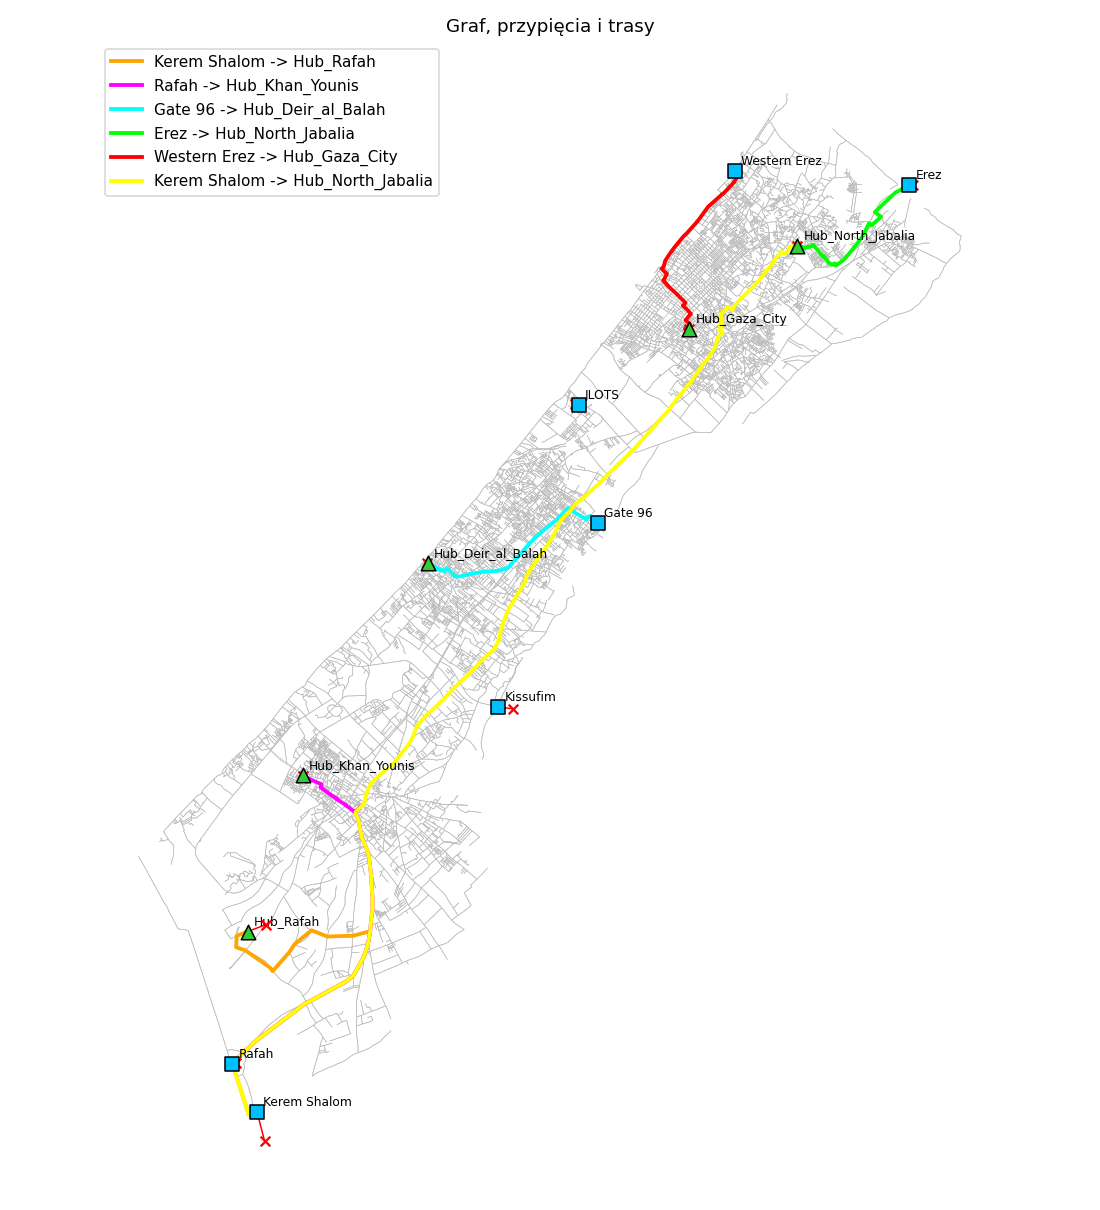

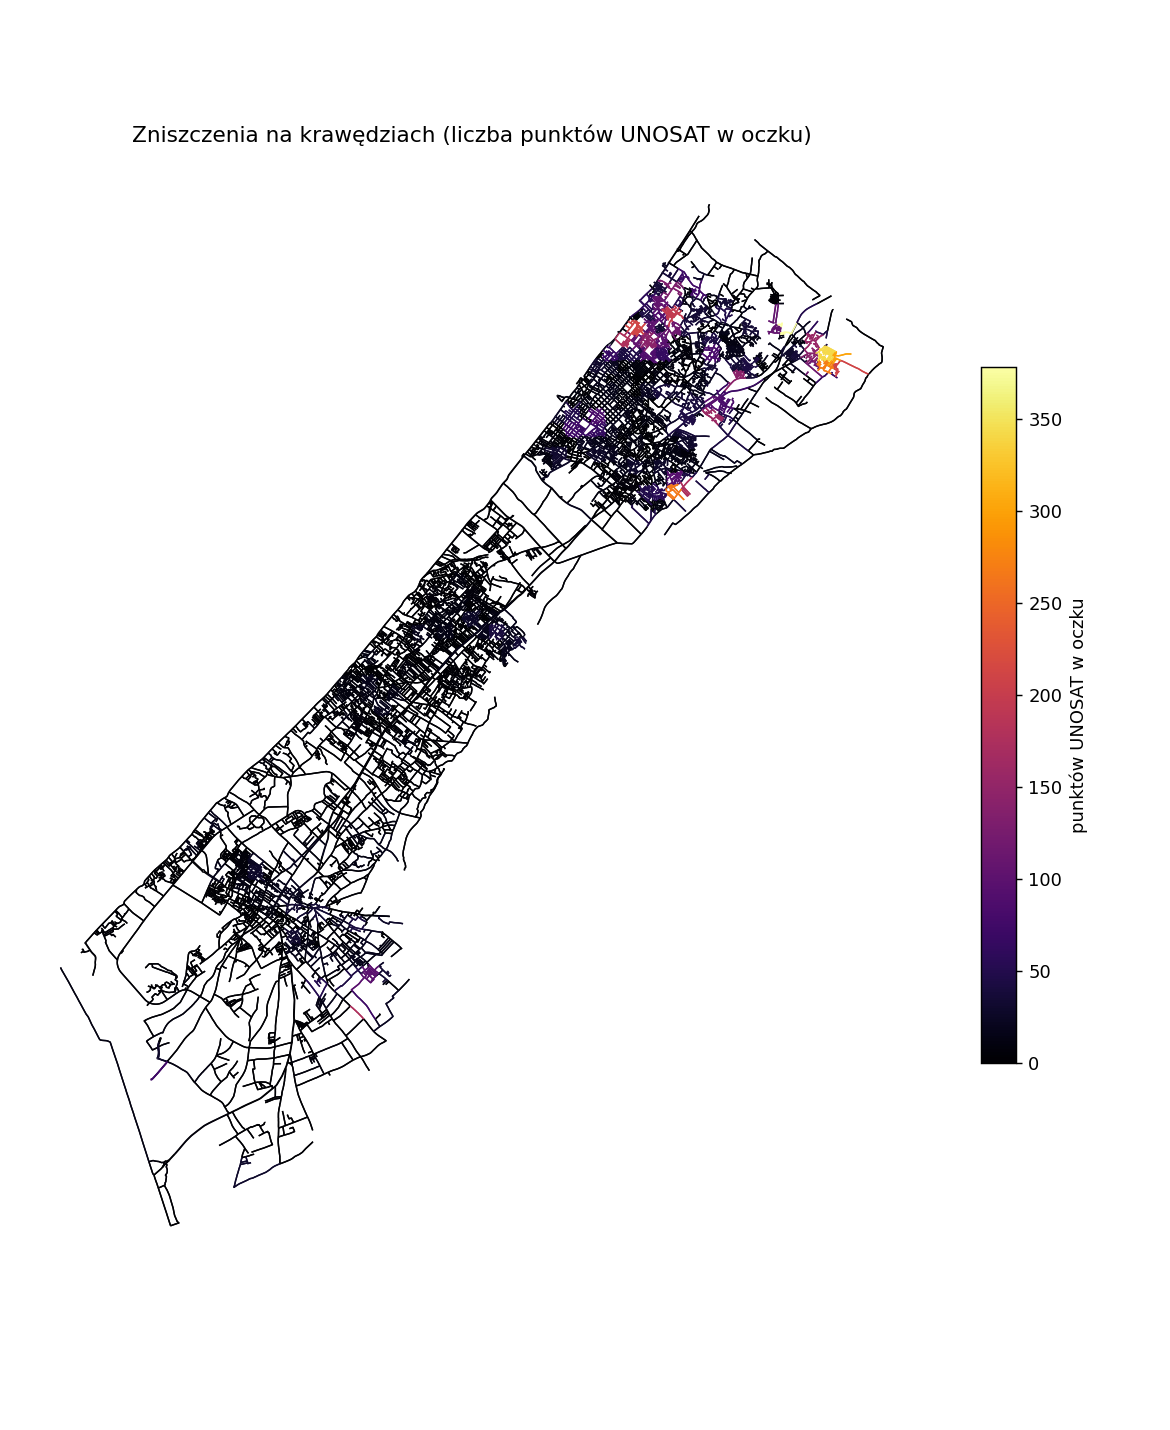

In [8]:
# Wyświetlenie mapy
from IPython.display import Image, display
import glob

for f in sorted(glob.glob("output/2023-11/*.png")):
    display(Image(f))